## ***DATASET IMPORT***

In [ ]:
!pip install roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 50.5 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11


In [ ]:
from roboflow import Roboflow
import os
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
rf = Roboflow(api_key="REw3QW5XIvpX1eqeL0Xa")
project = rf.workspace("crab-ceebx").project("eye_diseas-qnqbt")
version = project.version(1)
dataset = version.download("folder")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Eye_diseas-1 in folder:: 100%|██████████| 7311/7311 [00:02<00:00, 3367.38it/s]


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

In [ ]:
train_data = datasets.ImageFolder(root='/content/Eye_diseas-1/train', transform=transform)
valid_data = datasets.ImageFolder(root='/content/Eye_diseas-1/valid', transform=transform)
test_data  = datasets.ImageFolder(root='/content/Eye_diseas-1/test',  transform=transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=32, shuffle=False)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet50(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
num_classes = len(train_data.classes)
model.fc = nn.Linear(num_ftrs, num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 77.9MB/s]


In [ ]:
def train_model(model, train_loader, valid_loader, criterion, optimizer, num_epochs=100):
    train_losses = []
    valid_losses = []
    train_accuracies = []
    valid_accuracies = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = 100 * correct / total

        train_losses.append(train_loss)
        train_accuracies.append(train_acc)

        model.eval()
        running_val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for inputs, labels in valid_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item()

                _, preds = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (preds == labels).sum().item()

        val_loss = running_val_loss / len(valid_loader)
        val_acc = 100 * correct / total

        valid_losses.append(val_loss)
        valid_accuracies.append(val_acc)

        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%"
        )

    return train_losses, valid_losses, train_accuracies, valid_accuracies


In [ ]:
train_losses, valid_losses, train_accuracies, valid_accuracies = train_model(
    model, train_loader, valid_loader, criterion, optimizer, num_epochs=100
)


Epoch 1/100 | Train Loss: 0.8337 | Train Acc: 70.64% | Val Loss: 0.6105 | Val Acc: 77.93%
Epoch 2/100 | Train Loss: 0.5692 | Train Acc: 80.05% | Val Loss: 0.4871 | Val Acc: 83.28%
Epoch 3/100 | Train Loss: 0.5190 | Train Acc: 81.85% | Val Loss: 0.4990 | Val Acc: 82.52%
Epoch 4/100 | Train Loss: 0.4702 | Train Acc: 83.03% | Val Loss: 0.4686 | Val Acc: 83.55%
Epoch 5/100 | Train Loss: 0.4509 | Train Acc: 84.42% | Val Loss: 0.4585 | Val Acc: 83.96%
Epoch 6/100 | Train Loss: 0.4408 | Train Acc: 83.71% | Val Loss: 0.4911 | Val Acc: 81.36%
Epoch 7/100 | Train Loss: 0.4152 | Train Acc: 85.61% | Val Loss: 0.4044 | Val Acc: 84.92%
Epoch 8/100 | Train Loss: 0.4250 | Train Acc: 84.54% | Val Loss: 0.4113 | Val Acc: 84.92%
Epoch 9/100 | Train Loss: 0.3946 | Train Acc: 85.87% | Val Loss: 0.3990 | Val Acc: 85.47%
Epoch 10/100 | Train Loss: 0.3896 | Train Acc: 85.87% | Val Loss: 0.3787 | Val Acc: 85.68%
Epoch 11/100 | Train Loss: 0.3776 | Train Acc: 86.42% | Val Loss: 0.4052 | Val Acc: 85.26%
Epoch 12

In [ ]:
def evaluate_model(model, loader, data_classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    print(f"Accuracy: {acc:.4f}")

    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds, target_names=data_classes))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=data_classes,
                yticklabels=data_classes)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()


Validation Set Evaluation:
Accuracy: 0.8883

Classification Report:
                      precision    recall  f1-score   support

            Cataract       0.89      0.91      0.90       348
Diabetic Retinopathy       0.95      0.98      0.96       249
            Glaucoma       0.86      0.62      0.72       226
          Normal Eye       0.84      0.88      0.86       299
      Retina Disease       0.89      0.99      0.94       337

            accuracy                           0.89      1459
           macro avg       0.89      0.87      0.88      1459
        weighted avg       0.89      0.89      0.88      1459



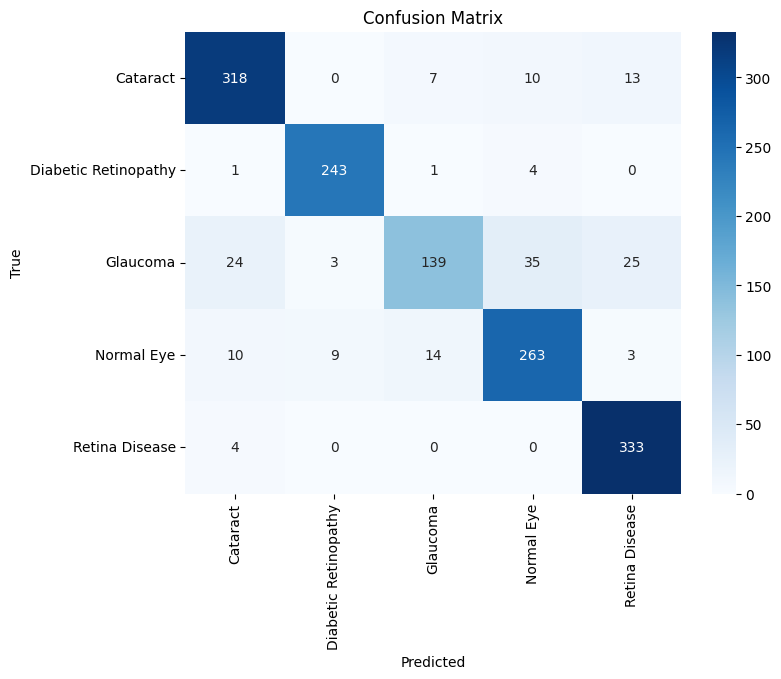

Test Set Evaluation:
Accuracy: 0.9068

Classification Report:
                      precision    recall  f1-score   support

            Cataract       0.93      0.94      0.94       176
Diabetic Retinopathy       0.98      0.93      0.96       119
            Glaucoma       0.83      0.64      0.72       100
          Normal Eye       0.86      0.92      0.89       152
      Retina Disease       0.91      0.99      0.95       183

            accuracy                           0.91       730
           macro avg       0.90      0.89      0.89       730
        weighted avg       0.91      0.91      0.90       730



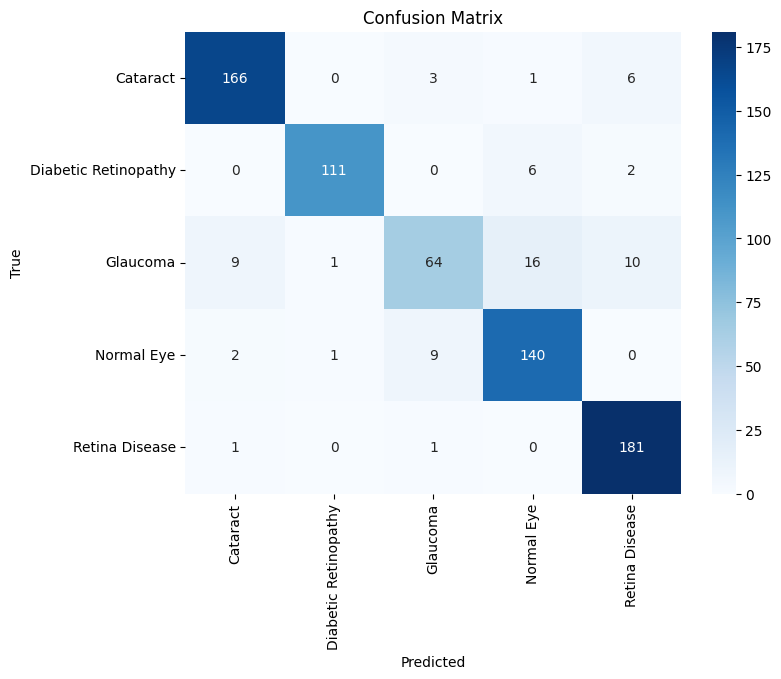

In [ ]:
print("Validation Set Evaluation:")
evaluate_model(model, valid_loader, valid_data.classes)

print("Test Set Evaluation:")
evaluate_model(model, test_loader, test_data.classes)

In [ ]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10,4))
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, valid_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss (ResNet50)')
plt.legend()
plt.grid(True)

# Save the figure
plt.savefig("/content/loss_curve_resnet50_100.png", dpi=300, bbox_inches='tight')

plt.show()


NameError: name 'train_losses' is not defined

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, valid_accuracies, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy (ResNet50)')
plt.legend()
plt.grid(True)

# Save the figure
plt.savefig("/content/accuracy_curve_resnet50_100.png", dpi=300, bbox_inches='tight')

plt.show()


In [ ]:
from google.colab import files

files.download("/content/loss_curve_resnet50_100.png")
files.download("/content/accuracy_curve_resnet50_100.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model_path = "/content/model_resnet50.pth"
torch.save(model.state_dict(), model_path)


In [ ]:
model_path = "/content/model_resnet50.pth"
torch.save(model.state_dict(), model_path)

from google.colab import files
files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed